In [1]:
import warnings
warnings.filterwarnings('ignore')

In [2]:
import itertools
import xarray as xr
import numpy as np
import matplotlib.pyplot as plt
import cmocean.cm as cmo
import cartopy.crs as ccrs
import pandas as pd
from scipy.signal import savgol_filter
import gsw
from glob import glob

# Average salinity fields

In [18]:
import itertools
import xarray as xr
import numpy as np
import matplotlib.pyplot as plt
import cmocean.cm as cmo
import cartopy.crs as ccrs
import pandas as pd
from scipy.signal import savgol_filter
import gsw
from glob import glob

import sys
sys.path.insert(0, '/home/danilo/model/analysis')
from functions import (make_map, subplots_structure, make_map_v2)

In [5]:
datadir = '/home/danilo/model/processing/data/glorys/smax2022'
zoomed_extent= [-45, -39, -27, -22]

flist = sorted(glob(f"{datadir}/*.nc"))

In [7]:
from xgcm import Grid
from xgcm.autogenerate import generate_grid_ds
import gsw

def prepare_isopycnal_surfaces(ds, target):
    ds['sigma_0'] = gsw.sigma0(ds['so'], ds['thetao'])
    
    # Generate 'full' dataset, which includes additional coordinate `depth_left` and appropriate attributes.
    ds_full = generate_grid_ds(ds, {'Z':'depth'})
    
    # Create grid object
    grid = Grid(ds_full, periodic=False)
    
    target_values = levels=np.arange(24., 25.6, 0.5)
    
    so_sigma = grid.transform(
      ds_full.so,
      'Z',
      target_values,
      target_data=ds_full.sigma_0
    )
    
    ds_sigma = xr.Dataset({'so': so_sigma})
    
    return ds_sigma

In [25]:
bathy = xr.open_dataset('../data/gebco_2019.nc')
# rename variables for a padronization
bathy = bathy.rename({'elevation': 'depth'})
bathy = bathy.where(bathy['depth'] < 0, drop=True)

# regional selection (for both dataset loaded)
lon_lower, lon_upper = zoomed_extent[0], zoomed_extent[1] #-50, -40
lat_lower, lat_upper = zoomed_extent[2], zoomed_extent[3] #-29, -23

# bathymetry
bathy = bathy.sel(lon=slice(lon_lower, lon_upper),
                lat=slice(lat_lower, lat_upper))

In [13]:
ds = xr.open_mfdataset(flist, chunks={'time': 30, 'longitude': 120, 'latitude': 120})
ds

<xarray.Dataset>
Dimensions:    (depth: 50, latitude: 361, time: 120, longitude: 385)
Coordinates:
  * depth      (depth) float32 0.494 1.541 2.646 ... 5.275e+03 5.728e+03
  * latitude   (latitude) float32 -46.0 -45.92 -45.83 ... -16.17 -16.08 -16.0
  * time       (time) datetime64[ns] 2022-02-01T12:00:00 ... 2022-05-31T12:00:00
  * longitude  (longitude) float32 -62.0 -61.92 -61.83 ... -30.17 -30.08 -30.0
Data variables:
    so         (time, depth, latitude, longitude) float32 dask.array<chunksize=(1, 50, 120, 120), meta=np.ndarray>
    thetao     (time, depth, latitude, longitude) float32 dask.array<chunksize=(1, 50, 120, 120), meta=np.ndarray>
    vo         (time, depth, latitude, longitude) float32 dask.array<chunksize=(1, 50, 120, 120), meta=np.ndarray>
    uo         (time, depth, latitude, longitude) float32 dask.array<chunksize=(1, 50, 120, 120), meta=np.ndarray>
    zos        (time, latitude, longitude) float32 dask.array<chunksize=(1, 120, 120), meta=np.ndarray>
Attributes: (12/13)
    producer:          CMEMS - Global Monitoring and Forecasting Centre
    title:             daily mean fields from Global Ocean Physics Analysis a...
    area:              Global
    Conventions:       CF-1.8
    credit:            E.U. Copernicus Marine Service Information (CMEMS)
    contact:           https://marine.copernicus.eu/contact
    ...                ...
    source:            MOI GLO12
    licence:           http://marine.copernicus.eu/services-portfolio/service...
    institution:       Mercator Ocean International
    _CoordSysBuilder:  ucar.nc2.dataset.conv.CF1Convention
    comment:           
    history:           Data extracted from dataset http://localhost:8080/thre...

In [30]:
ref_depth = 50
idz = np.argmin(np.abs(ds.depth.values - ref_depth))

dsplot1 = ds.isel(depth=idz).mean(dim='time')

target = np.arange(24., 25.6, 0.5) # from Silva et al (2023)
dsplot2 = prepare_isopycnal_surfaces(ds, target)
dsplot2 = dsplot2.mean(dim=['sigma_0', 'time'])

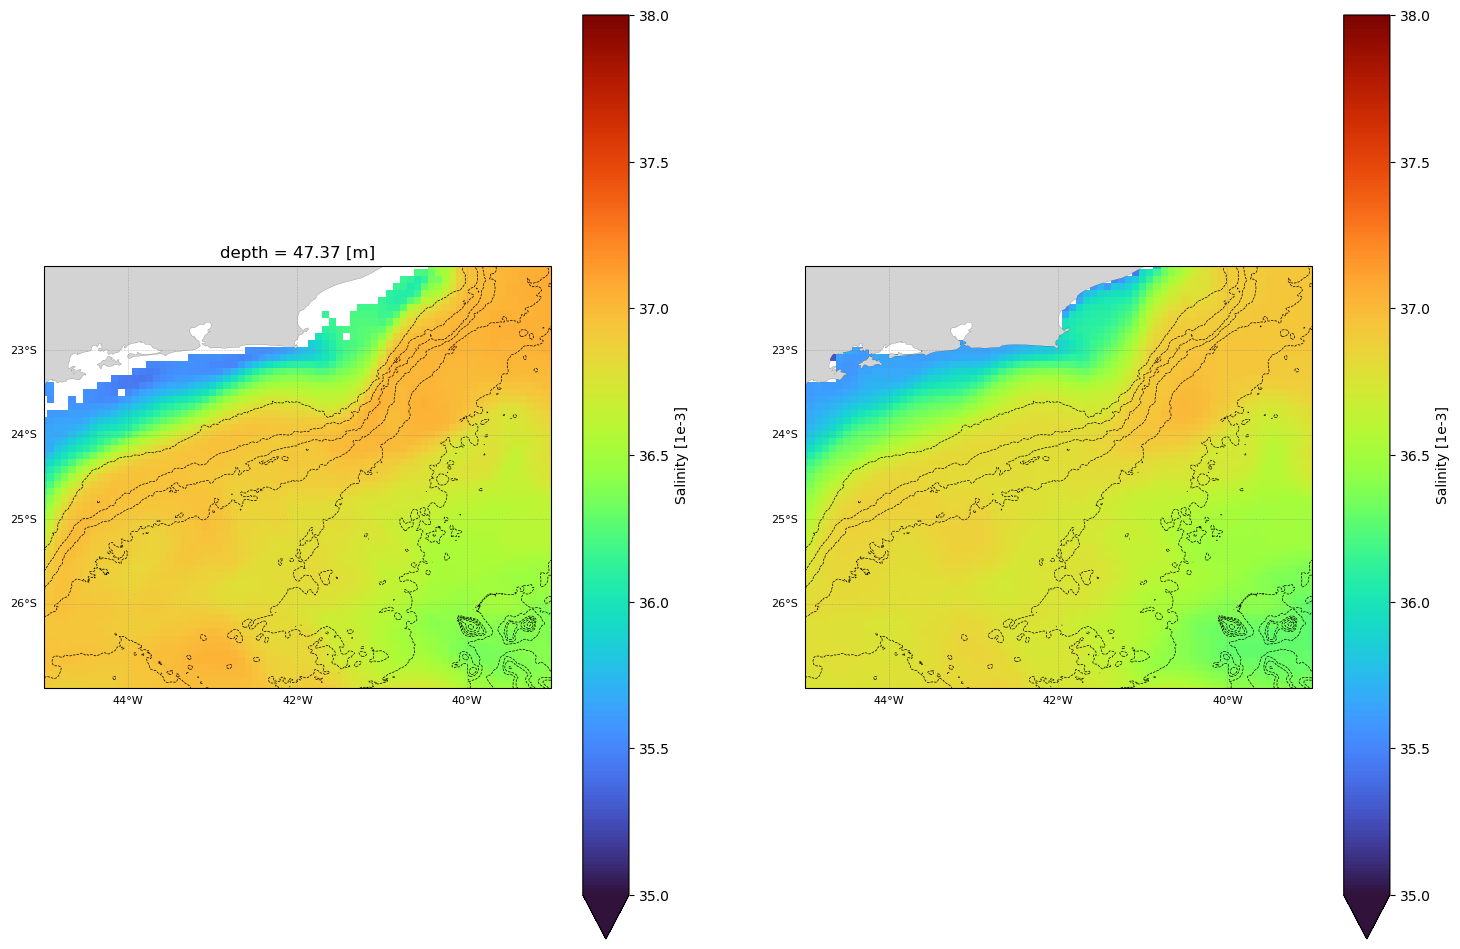

In [32]:
fig,axes = subplots_structure(2, 1, (25,10), 2)

ax = axes[0]
ax = make_map(ax=ax, facecolor='lightgray', deltax=2, deltay=1)
ax.set_extent(zoomed_extent)

# ax.plot(shelf['lon'], shelf['lat'], 'k--', lw=.5)
cr = bathy.depth.plot.contour(ax=ax,
                         levels=[-200, -1000, -1500, -2000, -2500, -3000, -4000, -5000], 
                         colors=('k'), linewidths=(0.5), linestyles=('--'))

dsplot1.so.plot.pcolormesh(ax=ax, cmap='turbo', vmax=38, vmin=35)
dsplot1.so.plot.contour(ax=ax, levels=[37.2], colors=('k'))

ax = axes[1]
ax = make_map(ax=ax, facecolor='lightgray', deltax=2, deltay=1)
ax.set_extent(zoomed_extent)

# ax.plot(shelf['lon'], shelf['lat'], 'k--', lw=.5)
cr = bathy.depth.plot.contour(ax=ax,
                         levels=[-200, -1000, -1500, -2000, -2500, -3000, -4000, -5000], 
                         colors=('k'), linewidths=(0.5), linestyles=('--'))
dsplot2.so.plot.pcolormesh(ax=ax, cmap='turbo', vmax=38, vmin=35)
dsplot2.so.plot.contour(ax=ax, levels=[37.2], colors=('k'))

In [29]:
dsplot2

<xarray.Dataset>
Dimensions:    (latitude: 361, time: 120, longitude: 385)
Coordinates:
  * latitude   (latitude) float32 -46.0 -45.92 -45.83 ... -16.17 -16.08 -16.0
  * time       (time) datetime64[ns] 2022-02-01T12:00:00 ... 2022-05-31T12:00:00
  * longitude  (longitude) float32 -62.0 -61.92 -61.83 ... -30.17 -30.08 -30.0
Data variables:
    so         (time, latitude, longitude) float32 dask.array<chunksize=(1, 120, 120), meta=np.ndarray>

# 75-m maps

In [59]:
ref_depth = 75

datadir = '/home/danilo/model/processing/data/glorys/smax2022'

flist = sorted(glob(f"{datadir}/*.nc"))
len(flist)

120

In [60]:
bathy = xr.open_dataset('../data/gebco_2019.nc')
# rename variables for a padronization
bathy = bathy.rename({'elevation': 'depth'})
bathy = bathy.where(bathy['depth'] < 0, drop=True)

# regional selection (for both dataset loaded)
lon_lower, lon_upper = zoomed_extent[0], zoomed_extent[1] #-50, -40
lat_lower, lat_upper = zoomed_extent[2], zoomed_extent[3] #-29, -23

# bathymetry
bathy = bathy.sel(lon=slice(lon_lower, lon_upper),
                lat=slice(lat_lower, lat_upper))

In [61]:
for n,fname in enumerate(flist):
    ds = xr.open_dataset(fname)
    

    idz = np.argmin(np.abs(ds.depth.values - ref_depth))

    fig,axes = subplots_structure(1, 1, (18,12), 1)
    ax = axes[0]
    ax = make_map(ax=ax, facecolor='lightgray', deltax=2, deltay=1)
    ax.set_extent(zoomed_extent)

    # ax.plot(shelf['lon'], shelf['lat'], 'k--', lw=.5)
    cr = bathy.depth.plot.contour(ax=ax,
                             levels=[-200, -1000, -1500, -2000, -2500, -3000, -4000, -5000], 
                             colors=('k'), linewidths=(0.5), linestyles=('--'))
    
    ds.so.isel(depth=idz).squeeze().plot.pcolormesh(ax=ax, cmap='turbo')
    ds.so.isel(depth=idz).squeeze().plot.contour(ax=ax, levels=[37.2], colors=('k'))

    plt.savefig(f"../figures/review_round1/glorys_{ref_depth}m/glorys_{ref_depth}_{pd.to_datetime(ds.time.values[0]).strftime('%Y%m%d')}.png",
               dpi=150,
               bbox_inches='tight')
    plt.close('all')

KeyboardInterrupt: 

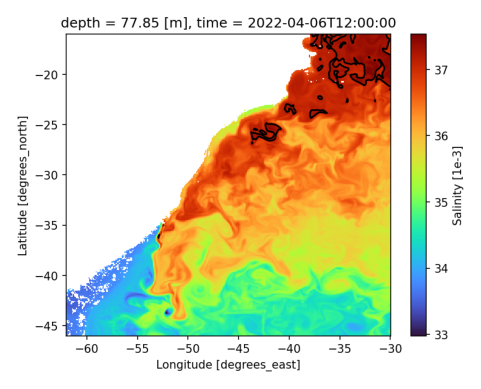

In [72]:
# Define the path where the images are stored
image_folder = '../figures/review_round1/glorys_75m'  # Update this to your folder

# List all files in the folder and sort them
image_files = sorted([f for f in os.listdir(image_folder) if f.endswith('.png') or f.endswith('.jpg')])

# Create a list to store image data
images = []
for image_file in image_files:
    img = cv2.imread(os.path.join(image_folder, image_file))
    images.append(img)

# Loop through images and display them as an animation
for img in images:
    plt.imshow(cv2.cvtColor(img, cv2.COLOR_BGR2RGB))  # Convert BGR to RGB for matplotlib
    plt.axis('off')  # Hide axes
    display(plt.gcf())  # Display the current frame
    sleep(0.05)  # Pause to create a frame rate
    clear_output(wait=True)  # Clear the output for the next frame

In [77]:
# Define video output parameters
output_video_path = f'{image_folder}/animation_output.mp4'  # The path where you want to save the video

import matplotlib.pyplot as plt
import numpy as np
import cv2
from matplotlib.backends.backend_agg import FigureCanvasAgg as FigureCanvas
from time import sleep

# Create a VideoWriter object to save the video in MP4 format with H.264 codec
# output_video_path = 'animation_output.mp4'  # Save as .mp4
frame_rate = 10  # Frames per second

# Define resolution for the video
height, width = 480, 640  # Can be adjusted based on your figure size

# FourCC code for H.264 video codec (for .mp4)
fourcc = cv2.VideoWriter_fourcc(*'mp4v')  # 'mp4v' is for .mp4 videos, 'XVID' is for .avi

# Create VideoWriter object
out = cv2.VideoWriter(output_video_path, fourcc, frame_rate, (width, height))

# Generate some figures (e.g., for an animation)
for i in range(100):  # Loop through 100 frames (or whatever number you need)
    # Create a new figure
    fig, ax = plt.subplots(figsize=(6.4, 4.8))  # Adjust the figure size if needed
    ax.plot(np.sin(np.linspace(0, 2 * np.pi, 100) + i / 10))  # Example plot (animated sine wave)
    
    # Convert the figure to a numpy array using FigureCanvas
    canvas = FigureCanvas(fig)
    canvas.draw()  # Draw the figure on the canvas
    img = np.array(canvas.buffer_rgba())  # Get the image in RGBA format
    
    # Convert RGBA to BGR (OpenCV uses BGR instead of RGB)
    img_bgr = cv2.cvtColor(img, cv2.COLOR_RGBA2BGR)
    
    # Resize the image to match the video resolution (optional, if needed)
    img_bgr = cv2.resize(img_bgr, (width, height))
    
    # Write the frame to the video
    out.write(img_bgr)
    
    # Optionally, display in the notebook (for visualization purposes)
    plt.close(fig)  # Close the figure to free memory
    sleep(0.1)  # Delay to simulate animation speed

# Release the VideoWriter and finalize the video
out.release()

# Optionally, display the video in Jupyter Lab
from IPython.display import Video
Video(output_video_path)


In [78]:
output_video_path

'../figures/review_round1/glorys_75m/animation_output.mp4'

In [79]:
%%HTML
<video width="320" height="240" controls>
  <source src="p../figures/review_round1/glorys_75m/animation_output.mp4" type="video/mp4">
</video>

# 50-m maps

In [14]:
ref_depth = 50

datadir = '/home/danilo/model/processing/data/glorys/smax2022'

flist = sorted(glob(f"{datadir}/*.nc"))
len(flist)

120

In [15]:
bathy = xr.open_dataset('../data/gebco_2019.nc')
# rename variables for a padronization
bathy = bathy.rename({'elevation': 'depth'})
bathy = bathy.where(bathy['depth'] < 0, drop=True)

# regional selection (for both dataset loaded)
lon_lower, lon_upper = zoomed_extent[0], zoomed_extent[1] #-50, -40
lat_lower, lat_upper = zoomed_extent[2], zoomed_extent[3] #-29, -23

# bathymetry
bathy = bathy.sel(lon=slice(lon_lower, lon_upper),
                lat=slice(lat_lower, lat_upper))

In [16]:
for n,fname in enumerate(flist):
    ds = xr.open_dataset(fname)
    

    idz = np.argmin(np.abs(ds.depth.values - ref_depth))

    fig,axes = subplots_structure(1, 1, (18,12), 1)
    ax = axes[0]
    ax = make_map(ax=ax, facecolor='lightgray', deltax=2, deltay=1)
    ax.set_extent(zoomed_extent)

    # ax.plot(shelf['lon'], shelf['lat'], 'k--', lw=.5)
    cr = bathy.depth.plot.contour(ax=ax,
                             levels=[-200, -1000, -1500, -2000, -2500, -3000, -4000, -5000], 
                             colors=('k'), linewidths=(0.5), linestyles=('--'))
    
    ds.so.isel(depth=idz).squeeze().plot.pcolormesh(ax=ax, cmap='turbo', vmin=33, vmax=38)
    ds.so.isel(depth=idz).squeeze().plot.contour(ax=ax, levels=[36.5, 37.2], colors=('g', 'k'))

    plt.savefig(f"../figures/review_round1/glorys_50m/glorys_{ref_depth}_{pd.to_datetime(ds.time.values[0]).strftime('%Y%m%d')}.png",
               dpi=150,
               bbox_inches='tight')
    plt.close('all')

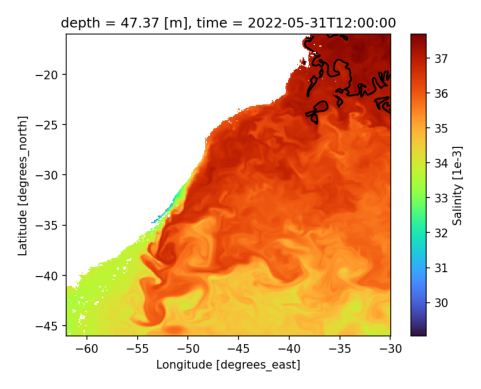

In [85]:
# Define the path where the images are stored
image_folder = '../figures/review_round1/glorys_50m'  # Update this to your folder
run_video_from_images(image_folder)

In [82]:
def run_video_from_images(image_folder):
    # List all files in the folder and sort them
    image_files = sorted([f for f in os.listdir(image_folder) if f.endswith('.png') or f.endswith('.jpg')])
    
    # Create a list to store image data
    images = []
    for image_file in image_files:
        img = cv2.imread(os.path.join(image_folder, image_file))
        images.append(img)
    
    # Loop through images and display them as an animation
    for img in images:
        plt.imshow(cv2.cvtColor(img, cv2.COLOR_BGR2RGB))  # Convert BGR to RGB for matplotlib
        plt.axis('off')  # Hide axes
        display(plt.gcf())  # Display the current frame
        sleep(0.05)  # Pause to create a frame rate
        clear_output(wait=True)  # Clear the output for the next frame

# 25-26 isopycnals maps

To run this section, need to change kernel to JUPYTER

In [3]:
import warnings
warnings.filterwarnings('ignore')

In [17]:
import itertools
import xarray as xr
import numpy as np
import matplotlib.pyplot as plt
import cmocean.cm as cmo
import cartopy.crs as ccrs
import pandas as pd
from scipy.signal import savgol_filter
import gsw
from glob import glob

xr.set_options(keep_attrs=True)

from utils import make_map, subplots_structure, get_shelf_edge

In [18]:
from xgcm import Grid
from xgcm.autogenerate import generate_grid_ds
import gsw

In [19]:
def prepare_isopycnal_surfaces(ds, target):
    ds['sigma_0'] = gsw.sigma0(ds['so'], ds['thetao'])
    
    # Generate 'full' dataset, which includes additional coordinate `depth_left` and appropriate attributes.
    ds_full = generate_grid_ds(ds, {'Z':'depth'})
    
    # Create grid object
    grid = Grid(ds_full, periodic=False)
    
    target_values = levels=np.arange(24., 25.6, 0.5)
    
    so_sigma = grid.transform(
      ds_full.so,
      'Z',
      target_values,
      target_data=ds_full.sigma_0
    )
    
    ds_sigma = xr.Dataset({'so': so_sigma})
    
    return ds_sigma

In [20]:
target = np.arange(24., 25.6, 0.5) # from Silva et al (2023)
zoomed_extent= [-45, -39, -27, -22]
datadir = '/home/danilo/model/processing/data/glorys/smax2022'

flist = sorted(glob(f"{datadir}/*.nc"))
len(flist)

120

In [21]:
bathy = xr.open_dataset('../data/gebco_2019.nc')
# rename variables for a padronization
bathy = bathy.rename({'elevation': 'depth'})
bathy = bathy.where(bathy['depth'] < 0, drop=True)

# regional selection (for both dataset loaded)
lon_lower, lon_upper = zoomed_extent[0], zoomed_extent[1] #-50, -40
lat_lower, lat_upper = zoomed_extent[2], zoomed_extent[3] #-29, -23

# bathymetry
bathy = bathy.sel(lon=slice(lon_lower, lon_upper),
                lat=slice(lat_lower, lat_upper))

In [22]:
for n,fname in enumerate(flist):
    ds = xr.open_dataset(fname)
    
    ds_sigma = prepare_isopycnal_surfaces(ds, target)
    
    dsplot = ds_sigma.mean(dim='sigma_0')
    
    fig,axes = subplots_structure(1, 1, (18,12), 1)
    ax = axes[0]
    ax = make_map(ax=ax, facecolor='lightgray', deltax=2, deltay=1)
    ax.set_extent(zoomed_extent)

    # ax.plot(shelf['lon'], shelf['lat'], 'k--', lw=.5)
    cr = bathy.depth.plot.contour(ax=ax,
                             levels=[-200, -1000, -1500, -2000, -2500, -3000, -4000, -5000], 
                             colors=('k'), linewidths=(0.5), linestyles=('--'))
    
    dsplot.isel(time=0).so.plot.pcolormesh(ax=ax, x='longitude', y='latitude', cmap='turbo', vmin=33, vmax=38)
    dsplot.isel(time=0).so.plot.contour(ax=ax, levels=[36.5, 37.2], colors=('g', 'k'))

    plt.savefig(f"../figures/review_round1/glorys_isopycnal/glorys_isopycnal_{pd.to_datetime(ds.time.values[0]).strftime('%Y%m%d')}.png",
               dpi=150,
               bbox_inches='tight')
    plt.close('all')

# 50-m and isopycnal layer together

### Figure for manuscript

In [3]:
import warnings
warnings.filterwarnings('ignore')

In [4]:
import itertools
import xarray as xr
import numpy as np
import matplotlib.pyplot as plt
import cmocean.cm as cmo
import cartopy.crs as ccrs
import pandas as pd
from scipy.signal import savgol_filter
import gsw
from glob import glob
import matplotlib.patches as patches

xr.set_options(keep_attrs=True)

from utils import make_map, subplots_structure, get_shelf_edge

In [5]:
from xgcm import Grid
from xgcm.autogenerate import generate_grid_ds
import gsw

In [6]:
def prepare_isopycnal_surfaces(ds, target):
    ds['sigma_0'] = gsw.sigma0(ds['so'], ds['thetao'])
    
    # Generate 'full' dataset, which includes additional coordinate `depth_left` and appropriate attributes.
    ds_full = generate_grid_ds(ds, {'Z':'depth'})
    
    # Create grid object
    grid = Grid(ds_full, periodic=False)
    
    target_values = levels=np.arange(24., 25.6, 0.5)
    
    so_sigma = grid.transform(
      ds_full.so,
      'Z',
      target_values,
      target_data=ds_full.sigma_0
    )
    
    ds_sigma = xr.Dataset({'so': so_sigma})
    
    return ds_sigma

In [7]:
ref_depth = 50
target = np.arange(24., 25.6, 0.5) # from Silva et al (2023)
zoomed_extent= [-45, -39, -27, -22]

datadir = '/home/danilo/model/processing/data/glorys/smax2022'

flist = sorted(glob(f"{datadir}/*.nc"))
len(flist)

120

In [8]:
bathy = xr.open_dataset('../data/gebco_2019.nc')
# rename variables for a padronization
bathy = bathy.rename({'elevation': 'depth'})
bathy = bathy.where(bathy['depth'] < 0, drop=True)

# regional selection (for both dataset loaded)
lon_lower, lon_upper = zoomed_extent[0], zoomed_extent[1] #-50, -40
lat_lower, lat_upper = zoomed_extent[2], zoomed_extent[3] #-29, -23

# bathymetry
bathy = bathy.sel(lon=slice(lon_lower, lon_upper),
                lat=slice(lat_lower, lat_upper))

In [9]:
# as a supplmentary material, needs to point the features I want to highlight on my main manuscript.
# Doing that using squares
dict_squares_50m  = {
    '20220218': ((-42.5, -25.85), 1, 0.35),
    '20220219': ((-42.8, -25.9), 1.5, 0.35),
    '20220220': ((-42.9, -25.95), 1.5, 0.42),
    '20220221': ((-42.99, -25.95), 1.5, 0.8),
    '20220222': ((-42.99, -25.95), 1.5, 0.8),
    '20220223': ((-43.1, -26.1), 1.3, 1.2),
    '20220224': ((-43.2, -25.99), 1., 1.40),
    '20220225': ((-43.22, -25.94), 0.8, 1.4),
    '20220226': ((-43.22, -25.92), 0.8, 1.6),
    '20220227': ((-43.22, -25.92), 0.8, 1.6),
    '20220228': ((-43.25, -25.98), 0.8, 1.8),
    '20220301': ((-43.05, -24.97), 0.45, 1.),
    '20220302': ((-43.1, -24.47), 0.45, 0.5),
    '20220303': ((-43.1, -24.47), 0.45, 0.5)    
}

dict_squares_isopycnal = {
    '20220304': ((-43.5, -23.9), 2, 1.),
    '20220305': ((-43.5, -23.9), 2, 1.),
    '20220306': ((-43.5, -23.9), 2, 1.),
    '20220307': ((-43.5, -23.9), 2, 1.),
    '20220308': ((-43.5, -23.9), 2, 1.),
    '20220309': ((-43.5, -23.9), 2, 1.),
    '20220310': ((-43.5, -23.9), 2, 1.),
    '20220311': ((-43.5, -23.9), 2, 1.),
    '20220312': ((-43.5, -23.9), 2, 1.),
    '20220313': ((-43.5, -23.9), 2, 1.),
    '20220314': ((-43.5, -23.9), 2, 1.),
    '20220315': ((-43.5, -23.9), 2, 1.),
    '20220316': ((-43.5, -23.9), 2, 1.),
    '20220317': ((-43.5, -23.9), 2, 1.),
    '20220318': ((-43.5, -23.9), 2, 1.),
    
}

locations = {
    '50m': dict_squares_50m,
    'isopycnal': dict_squares_isopycnal
}

locations.keys()

dict_keys(['50m', 'isopycnal'])

In [10]:
list_of_days = [ 17, 31] #'2022-02-18', '2022-03-03'

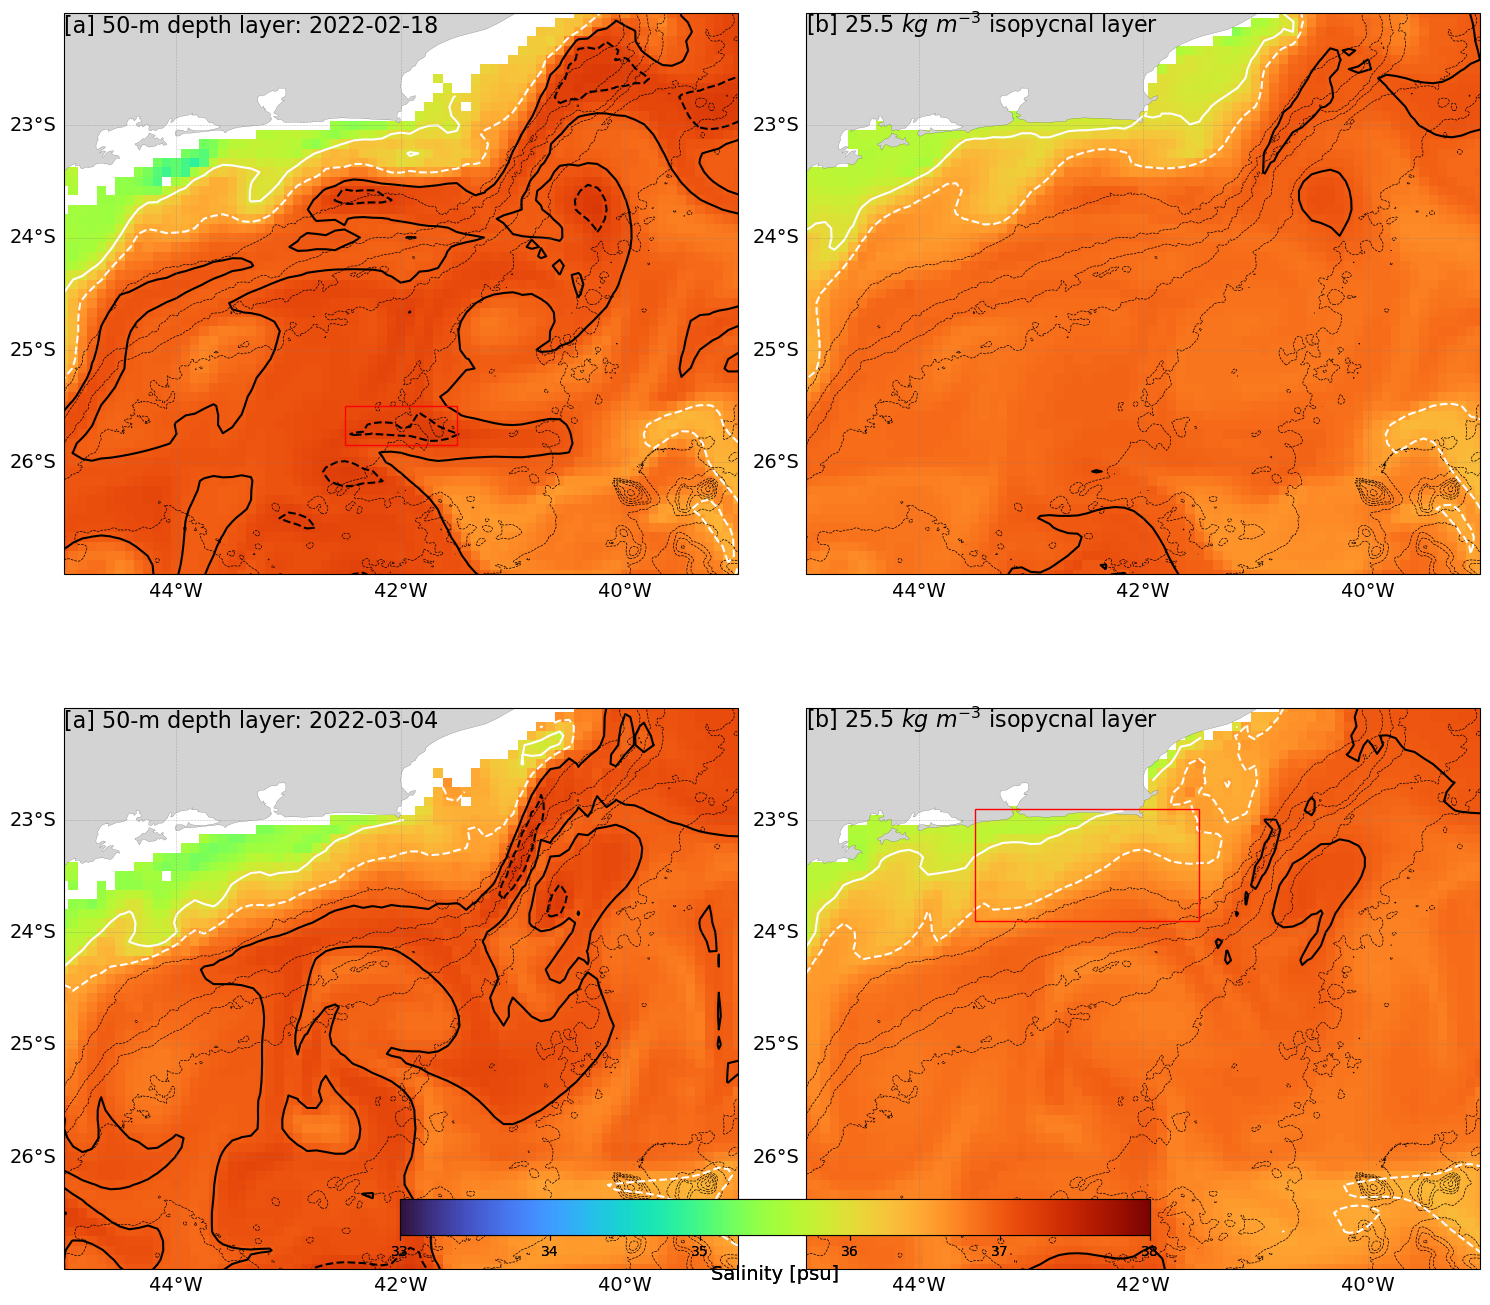

In [37]:
zoomed_extent= [-45, -39, -27, -22]

levels = [36, 36.5, 37., 37.2]
colors = ('w', 'w', 'k', 'k')
styles = ('-', '--', '-', '--')

# creating a letters list
letters = '[a] [b] [c] [d]'.split(' ')

fig,axes = subplots_structure(2, 2, (15,18), 4)

# for n,day in enumerate(list_of_days):
for n in [0,2]:
    if n == 0:
        day = list_of_days[n]
    elif n == 2:
        day = list_of_days[n-1]
        
    ds = xr.open_dataset(flist[day])
    datestr = pd.to_datetime(ds.time.values[0]).strftime('%Y-%m-%d')
    
    drawlineleft = True if n in [0,2] else False
    t = f"{letters[n]}"

    ax = axes[n]
    ax = make_map(ax=ax, facecolor='lightgray', deltax=2, deltay=1)
    ax.set_extent(zoomed_extent)

    # ax.plot(shelf['lon'], shelf['lat'], 'k--', lw=.5)
    cr = bathy.depth.plot.contour(ax=ax,
                             levels=[-200, -1000, -1500, -2000, -2500, -3000, -4000, -5000], 
                             colors=('k'), linewidths=(0.5), linestyles=('--'))

    idz = np.argmin(np.abs(ds.depth.values - ref_depth))
    
    pc = ds.so.isel(depth=idz).squeeze().plot.pcolormesh(ax=ax, cmap='turbo', vmin=33, vmax=38, add_colorbar=False)
    ds.so.isel(depth=idz).squeeze().plot.contour(ax=ax, levels=levels, colors=colors, linestyles=styles)
    
    ds_sigma = prepare_isopycnal_surfaces(ds, target)
    
    dsplot = ds_sigma.mean(dim='sigma_0')
    
    ax = axes[n+1]
    ax = make_map(ax=ax, facecolor='lightgray', deltax=2, deltay=1)
    ax.set_extent(zoomed_extent)

    # ax.plot(shelf['lon'], shelf['lat'], 'k--', lw=.5)
    cr = bathy.depth.plot.contour(ax=ax,
                             levels=[-200, -1000, -1500, -2000, -2500, -3000, -4000, -5000], 
                             colors=('k'), linewidths=(0.5), linestyles=('--'))
    
    pc = dsplot.isel(time=0).so.plot.pcolormesh(ax=ax, x='longitude', y='latitude', cmap='turbo', 
                                           vmin=33, vmax=38, add_colorbar=False)
    dsplot.isel(time=0).so.plot.contour(ax=ax, levels=levels, colors=colors, linestyles=styles)

    plt.tight_layout()
    
    cax = fig.add_axes([0.27, 0.17, 0.5, 0.02])
    cbar = fig.colorbar(pc, cax=cax, orientation='horizontal')
    cbar.set_label('Salinity [psu]', fontsize=14)
    _ = [ax.set_title('') for ax in axes]
    _ = axes[n].set_title(f'[a] 50-m depth layer: {datestr}', loc='left', fontsize=16, y=0.95)
    _ = axes[n+1].set_title(r'[b] 25.5 $kg\ m^{-3}$ isopycnal layer', loc='left', fontsize=16, y=0.95)

    # checking squares to be plotted based on the date
    if pd.to_datetime(ds.time.values[0]).strftime('%Y%m%d') in locations['50m'].keys():
        loc = locations['50m'][pd.to_datetime(ds.time.values[0]).strftime('%Y%m%d')]
        
        # Create a Rectangle patch
        rect = patches.Rectangle(loc[0], loc[1], loc[2], linewidth=1, edgecolor='r', facecolor='none', zorder=20)
        
        # Add the patch to the Axes
        axes[n].add_patch(rect)

    # checking squares to be plotted based on the date
    if pd.to_datetime(ds.time.values[0]).strftime('%Y%m%d') in locations['isopycnal'].keys():
        loc = locations['isopycnal'][pd.to_datetime(ds.time.values[0]).strftime('%Y%m%d')]
        
        # Create a Rectangle patch
        rect = patches.Rectangle(loc[0], loc[1], loc[2], linewidth=1, edgecolor='r', facecolor='none', zorder=20)
        
        # Add the patch to the Axes
        axes[n+1].add_patch(rect)

### Figures for supplementary video

In [11]:
import warnings
warnings.filterwarnings('ignore')

In [12]:
import itertools
import xarray as xr
import numpy as np
import matplotlib.pyplot as plt
import cmocean.cm as cmo
import cartopy.crs as ccrs
import pandas as pd
from scipy.signal import savgol_filter
import gsw
from glob import glob
import matplotlib.patches as patches

xr.set_options(keep_attrs=True)

from utils import make_map, subplots_structure, get_shelf_edge

In [13]:
from xgcm import Grid
from xgcm.autogenerate import generate_grid_ds
import gsw

In [14]:
def prepare_isopycnal_surfaces(ds, target):
    ds['sigma_0'] = gsw.sigma0(ds['so'], ds['thetao'])
    
    # Generate 'full' dataset, which includes additional coordinate `depth_left` and appropriate attributes.
    ds_full = generate_grid_ds(ds, {'Z':'depth'})
    
    # Create grid object
    grid = Grid(ds_full, periodic=False)
    
    target_values = levels=np.arange(24., 25.6, 0.5)
    
    so_sigma = grid.transform(
      ds_full.so,
      'Z',
      target_values,
      target_data=ds_full.sigma_0
    )
    
    ds_sigma = xr.Dataset({'so': so_sigma})
    
    return ds_sigma

In [15]:
ref_depth = 50
target = np.arange(24., 25.6, 0.5) # from Silva et al (2023)
zoomed_extent= [-45, -39, -27, -22]

datadir = '/home/danilo/model/processing/data/glorys/smax2022'

flist = sorted(glob(f"{datadir}/*.nc"))
len(flist)

120

In [16]:
bathy = xr.open_dataset('../data/gebco_2019.nc')
# rename variables for a padronization
bathy = bathy.rename({'elevation': 'depth'})
bathy = bathy.where(bathy['depth'] < 0, drop=True)

# regional selection (for both dataset loaded)
lon_lower, lon_upper = zoomed_extent[0], zoomed_extent[1] #-50, -40
lat_lower, lat_upper = zoomed_extent[2], zoomed_extent[3] #-29, -23

# bathymetry
bathy = bathy.sel(lon=slice(lon_lower, lon_upper),
                lat=slice(lat_lower, lat_upper))

In [17]:
# as a supplmentary material, needs to point the features I want to highlight on my main manuscript.
# Doing that using squares
dict_squares_50m  = {
    '20220218': ((-42.5, -25.85), 1, 0.35),
    '20220219': ((-42.8, -25.9), 1.5, 0.35),
    '20220220': ((-42.9, -25.95), 1.5, 0.42),
    '20220221': ((-42.99, -25.95), 1.5, 0.8),
    '20220222': ((-42.99, -25.95), 1.5, 0.8),
    '20220223': ((-43.1, -26.1), 1.3, 1.2),
    '20220224': ((-43.2, -25.99), 1., 1.40),
    '20220225': ((-43.22, -25.94), 0.8, 1.4),
    '20220226': ((-43.22, -25.92), 0.8, 1.6),
    '20220227': ((-43.22, -25.92), 0.8, 1.6),
    '20220228': ((-43.25, -25.98), 0.8, 1.8),
    '20220301': ((-43.05, -24.97), 0.45, 1.),
    '20220302': ((-43.1, -24.47), 0.45, 0.5),
    '20220303': ((-43.1, -24.47), 0.45, 0.5)    
}

dict_squares_isopycnal = {
    '20220304': ((-43.5, -23.9), 2, 1.),
    '20220305': ((-43.5, -23.9), 2, 1.),
    '20220306': ((-43.5, -23.9), 2, 1.),
    '20220307': ((-43.5, -23.9), 2, 1.),
    '20220308': ((-43.5, -23.9), 2, 1.),
    '20220309': ((-43.5, -23.9), 2, 1.),
    '20220310': ((-43.5, -23.9), 2, 1.),
    '20220311': ((-43.5, -23.9), 2, 1.),
    '20220312': ((-43.5, -23.9), 2, 1.),
    '20220313': ((-43.5, -23.9), 2, 1.),
    '20220314': ((-43.5, -23.9), 2, 1.),
    '20220315': ((-43.5, -23.9), 2, 1.),
    '20220316': ((-43.5, -23.9), 2, 1.),
    '20220317': ((-43.5, -23.9), 2, 1.),
    '20220318': ((-43.5, -23.9), 2, 1.),
    
}

locations = {
    '50m': dict_squares_50m,
    'isopycnal': dict_squares_isopycnal
}

locations.keys()

dict_keys(['50m', 'isopycnal'])

In [18]:
fname = flist[0]
ds = xr.open_dataset(fname)
print(4.737369e+01)

47.37369


In [19]:
plotHowMany = None # only to  make easier to plot everything or just a single date for tests

levels = [36, 36.5, 37., 37.2]
colors = ('w', 'w', 'k', 'k')
styles = ('-', '--', '-', '--')

for n,fname in enumerate(flist[:plotHowMany]):
    ds = xr.open_dataset(fname)
    datestr = pd.to_datetime(ds.time.values[0]).strftime('%Y-%m-%d')
    
    fig,axes = subplots_structure(2, 1, (18,12), 2)
    
    ax = axes[0]
    ax = make_map(ax=ax, facecolor='lightgray', deltax=2, deltay=1)
    ax.set_extent(zoomed_extent)

    # ax.plot(shelf['lon'], shelf['lat'], 'k--', lw=.5)
    cr = bathy.depth.plot.contour(ax=ax,
                             levels=[-200, -1000, -1500, -2000, -2500, -3000, -4000, -5000], 
                             colors=('k'), linewidths=(0.5), linestyles=('--'))

    idz = np.argmin(np.abs(ds.depth.values - ref_depth))
    
    pc = ds.so.isel(depth=idz).squeeze().plot.pcolormesh(ax=ax, cmap='turbo', vmin=33, vmax=38, add_colorbar=False)
    ds.so.isel(depth=idz).squeeze().plot.contour(ax=ax, levels=levels, colors=colors, linestyles=styles)
    
    ds_sigma = prepare_isopycnal_surfaces(ds, target)
    
    dsplot = ds_sigma.mean(dim='sigma_0')
    
    ax = axes[1]
    ax = make_map(ax=ax, facecolor='lightgray', deltax=2, deltay=1)
    ax.set_extent(zoomed_extent)

    # ax.plot(shelf['lon'], shelf['lat'], 'k--', lw=.5)
    cr = bathy.depth.plot.contour(ax=ax,
                             levels=[-200, -1000, -1500, -2000, -2500, -3000, -4000, -5000], 
                             colors=('k'), linewidths=(0.5), linestyles=('--'))
    
    pc = dsplot.isel(time=0).so.plot.pcolormesh(ax=ax, x='longitude', y='latitude', cmap='turbo', 
                                           vmin=33, vmax=38, add_colorbar=False)
    dsplot.isel(time=0).so.plot.contour(ax=ax, levels=levels, colors=colors, linestyles=styles)

    plt.tight_layout()
    
    cax = fig.add_axes([0.27, 0.17, 0.5, 0.02])
    cbar = fig.colorbar(pc, cax=cax, orientation='horizontal')
    cbar.set_label('Salinity [psu]', fontsize=14)
    _ = [ax.set_title('') for ax in axes]
    _ = axes[0].set_title(f'[a] 50-m depth layer: {datestr}', loc='left', fontsize=16, y=0.95)
    _ = axes[1].set_title(r'[b] 25.5 $kg\ m^{-3}$ isopycnal layer', loc='left', fontsize=16, y=0.95)

    # checking squares to be plotted based on the date
    if pd.to_datetime(ds.time.values[0]).strftime('%Y%m%d') in locations['50m'].keys():
        loc = locations['50m'][pd.to_datetime(ds.time.values[0]).strftime('%Y%m%d')]
        
        # Create a Rectangle patch
        rect = patches.Rectangle(loc[0], loc[1], loc[2], linewidth=1, edgecolor='r', facecolor='none', zorder=20)
        
        # Add the patch to the Axes
        axes[0].add_patch(rect)

    # checking squares to be plotted based on the date
    if pd.to_datetime(ds.time.values[0]).strftime('%Y%m%d') in locations['isopycnal'].keys():
        loc = locations['isopycnal'][pd.to_datetime(ds.time.values[0]).strftime('%Y%m%d')]
        
        # Create a Rectangle patch
        rect = patches.Rectangle(loc[0], loc[1], loc[2], linewidth=1, edgecolor='r', facecolor='none', zorder=20)
        
        # Add the patch to the Axes
        axes[1].add_patch(rect)
    
    plt.savefig(f"../figures/review_round1/glorys_combined_50m_and_isopycnal_{pd.to_datetime(ds.time.values[0]).strftime('%Y%m%d')}.png",
               dpi=150,
               bbox_inches='tight')

    if plotHowMany != 1:
        plt.close('all')

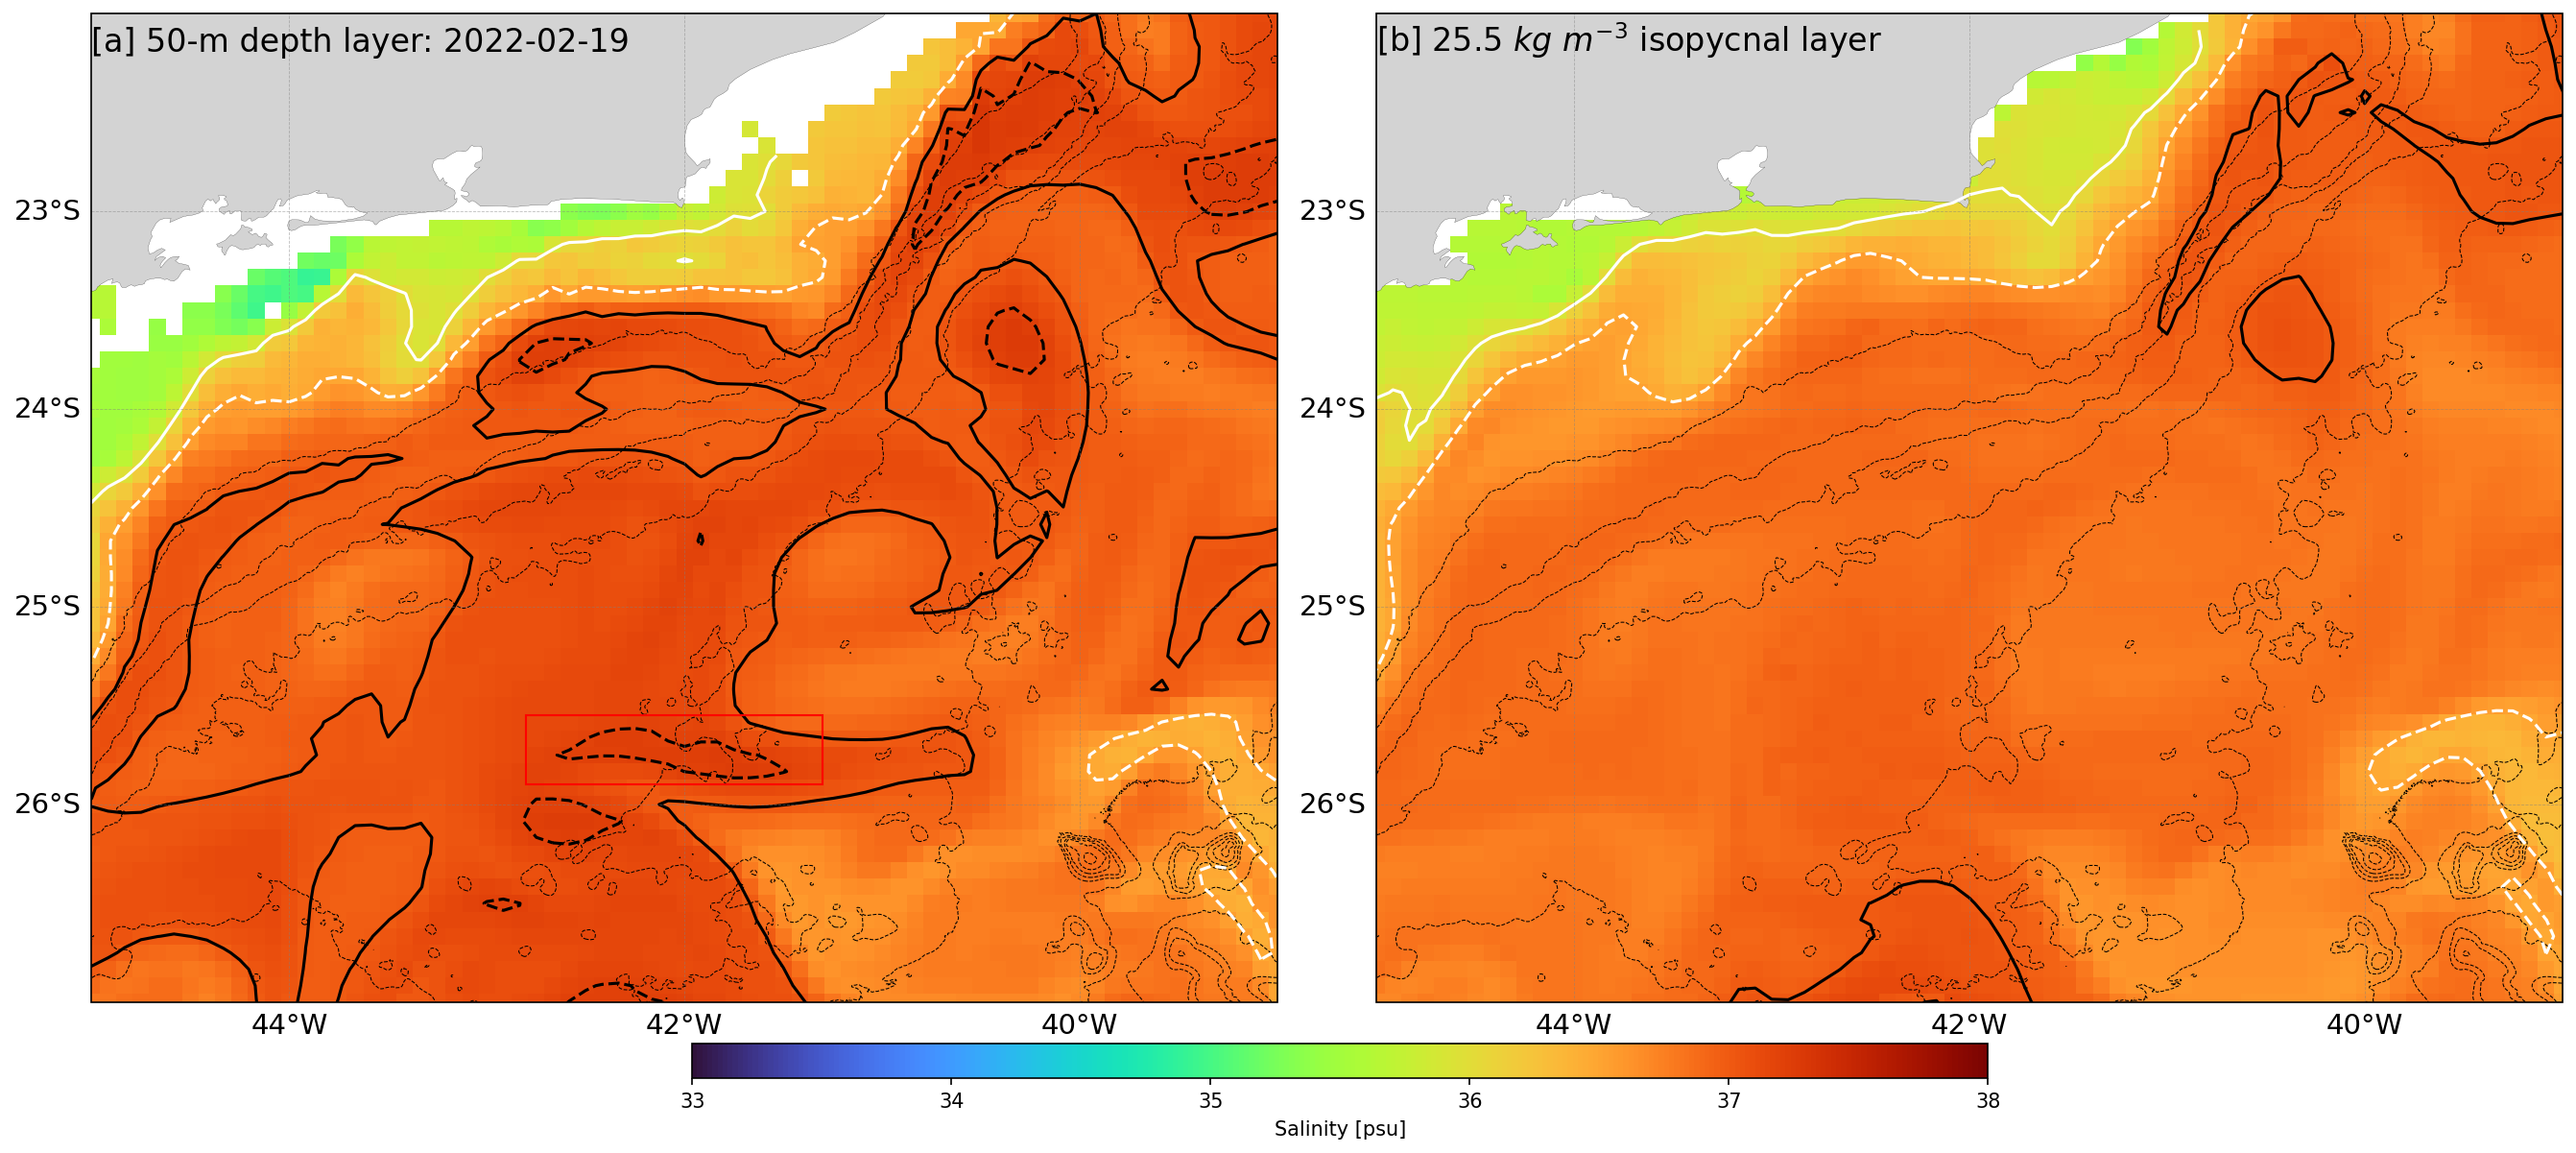

In [37]:
from IPython.display import Image
Image(filename=f"../figures/review_round1/glorys_combined_50m_and_isopycnal_20220219.png", width=1500) 

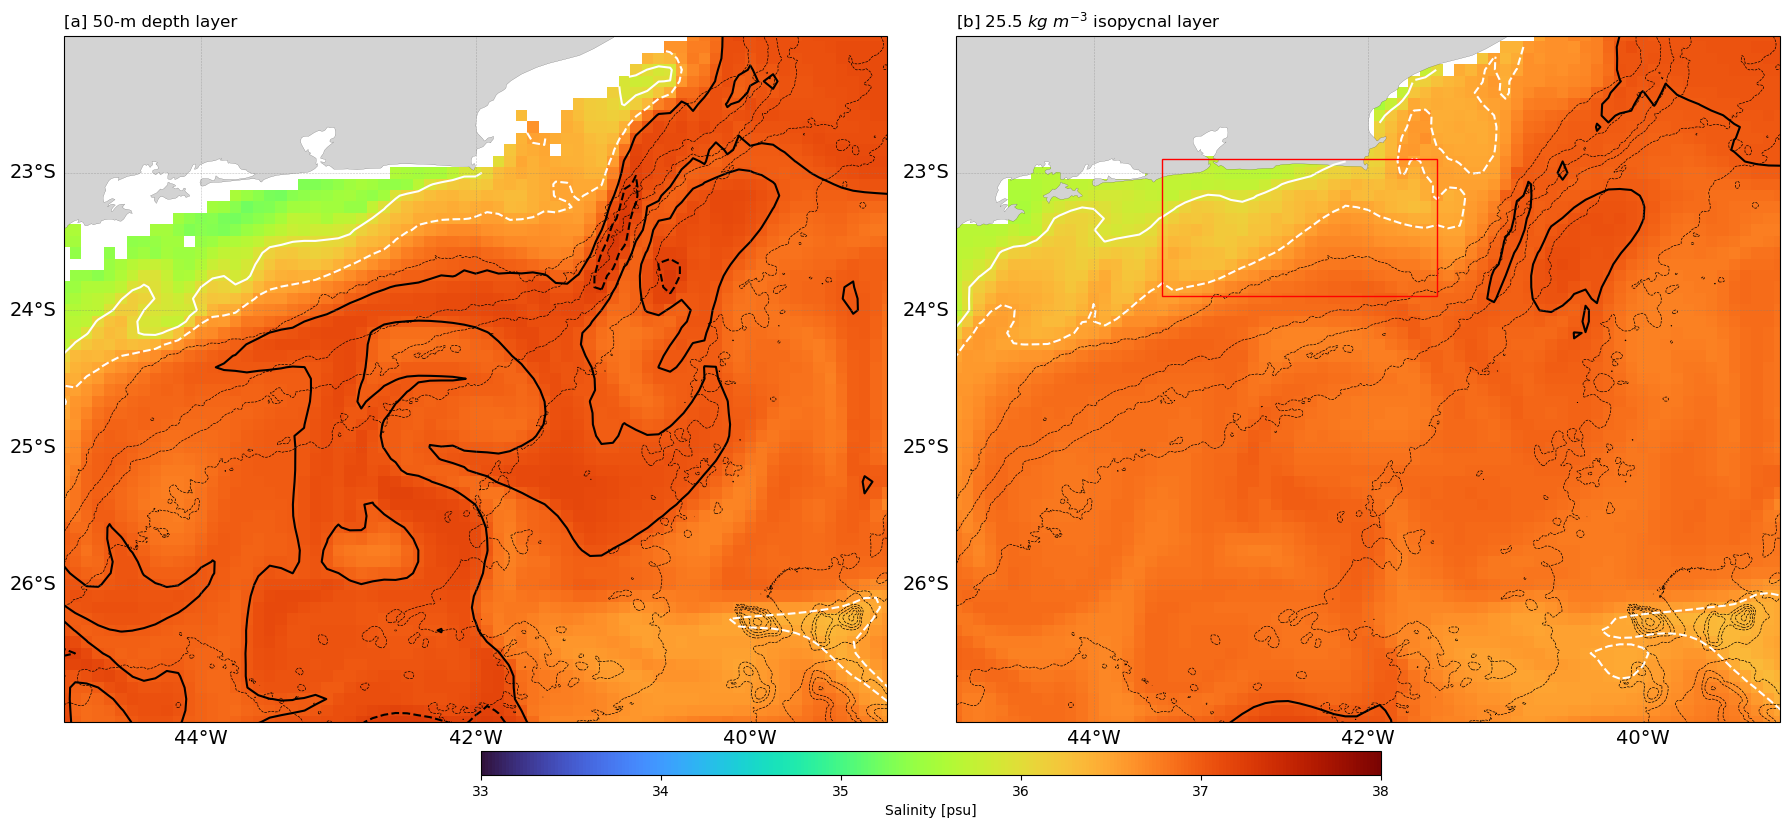

In [15]:
levels = [36, 36.5, 37., 37.2]
colors = ('w', 'w', 'k', 'k')
styles = ('-', '--', '-', '--')

fname = flist[32]

ds = xr.open_dataset(fname)
fig,axes = subplots_structure(2, 1, (18,12), 2)

ax = axes[0]
ax = make_map(ax=ax, facecolor='lightgray', deltax=2, deltay=1)
ax.set_extent(zoomed_extent)

# ax.plot(shelf['lon'], shelf['lat'], 'k--', lw=.5)
cr = bathy.depth.plot.contour(ax=ax,
                         levels=[-200, -1000, -1500, -2000, -2500, -3000, -4000, -5000], 
                         colors=('k'), linewidths=(0.5), linestyles=('--'))
idz = np.argmin(np.abs(ds.depth.values - ref_depth))

pc = ds.so.isel(depth=idz).squeeze().plot.pcolormesh(ax=ax, cmap='turbo', vmin=33, vmax=38, add_colorbar=False)
ds.so.isel(depth=idz).squeeze().plot.contour(ax=ax, levels=levels, colors=colors, linestyles=styles)

ds_sigma = prepare_isopycnal_surfaces(ds, target)

dsplot = ds_sigma.mean(dim='sigma_0')

ax = axes[1]
ax = make_map(ax=ax, facecolor='lightgray', deltax=2, deltay=1)
ax.set_extent(zoomed_extent)

# ax.plot(shelf['lon'], shelf['lat'], 'k--', lw=.5)
cr = bathy.depth.plot.contour(ax=ax,
                         levels=[-200, -1000, -1500, -2000, -2500, -3000, -4000, -5000], 
                         colors=('k'), linewidths=(0.5), linestyles=('--'))

pc = dsplot.isel(time=0).so.plot.pcolormesh(ax=ax, x='longitude', y='latitude', cmap='turbo', 
                                       vmin=33, vmax=38, add_colorbar=False)
dsplot.isel(time=0).so.plot.contour(ax=ax, levels=levels, colors=colors, linestyles=styles)

plt.tight_layout()

cax = fig.add_axes([0.27, 0.17, 0.5, 0.02])
cbar = fig.colorbar(pc, cax=cax, orientation='horizontal')
cbar.set_label('Salinity [psu]')
_ = [ax.set_title('') for ax in axes]
_ = axes[0].set_title('[a] 50-m depth layer', loc='left')
_ = axes[1].set_title(r'[b] 25.5 $kg\ m^{-3}$ isopycnal layer', loc='left')

# checking squares to be plotted based on the date
if pd.to_datetime(ds.time.values[0]).strftime('%Y%m%d') in locations['50m'].keys():
    loc = locations['50m'][pd.to_datetime(ds.time.values[0]).strftime('%Y%m%d')]
    
    # Create a Rectangle patch
    rect = patches.Rectangle(loc[0], loc[1], loc[2], linewidth=1, edgecolor='r', facecolor='none', zorder=20)
    
    # Add the patch to the Axes
    axes[0].add_patch(rect)

# checking squares to be plotted based on the date
if pd.to_datetime(ds.time.values[0]).strftime('%Y%m%d') in locations['isopycnal'].keys():
    loc = locations['isopycnal'][pd.to_datetime(ds.time.values[0]).strftime('%Y%m%d')]
    
    # Create a Rectangle patch
    rect = patches.Rectangle(loc[0], loc[1], loc[2], linewidth=1, edgecolor='r', facecolor='none', zorder=20)
    
    # Add the patch to the Axes
    axes[1].add_patch(rect)

# building movies

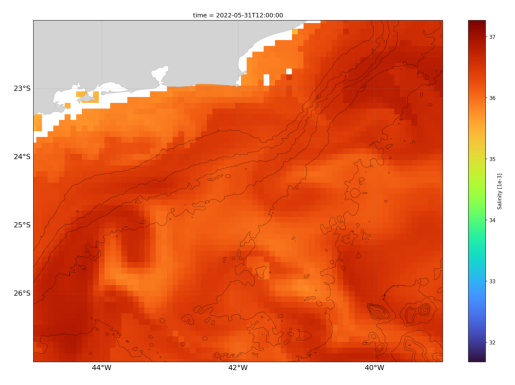

In [3]:
# activate other environment (build-movies) to run this
import cv2, os
from IPython.display import display, clear_output
from time import sleep
import matplotlib.pyplot as plt

# Define the path where the images are stored
image_folder = '../figures/review_round1/glorys_isopycnal'  # Update this to your folder

# List all files in the folder and sort them
image_files = sorted([f for f in os.listdir(image_folder) if f.endswith('.png') or f.endswith('.jpg')])

# Create a list to store image data
images = []
for image_file in image_files:
    img = cv2.imread(os.path.join(image_folder, image_file))
    images.append(img)

# Loop through images and display them as an animation
for img in images:
    plt.imshow(cv2.cvtColor(img, cv2.COLOR_BGR2RGB))  # Convert BGR to RGB for matplotlib
    plt.axis('off')  # Hide axes
    display(plt.gcf())  # Display the current frame
    sleep(0.05)  # Pause to create a frame rate
    clear_output(wait=True)  # Clear the output for the next frame

In [4]:
# Define video output parameters
output_video_path = f'{image_folder}/animation_output.mp4'  # The path where you want to save the video

import matplotlib.pyplot as plt
import numpy as np
import cv2
from matplotlib.backends.backend_agg import FigureCanvasAgg as FigureCanvas
from time import sleep

# Create a VideoWriter object to save the video in MP4 format with H.264 codec
# output_video_path = 'animation_output.mp4'  # Save as .mp4
frame_rate = 10  # Frames per second

# Define resolution for the video
height, width = 480, 640  # Can be adjusted based on your figure size

# FourCC code for H.264 video codec (for .mp4)
fourcc = cv2.VideoWriter_fourcc(*'mp4v')  # 'mp4v' is for .mp4 videos, 'XVID' is for .avi

# Create VideoWriter object
out = cv2.VideoWriter(output_video_path, fourcc, frame_rate, (width, height))

# Generate some figures (e.g., for an animation)
for i in range(100):  # Loop through 100 frames (or whatever number you need)
    # Create a new figure
    fig, ax = plt.subplots(figsize=(6.4, 4.8))  # Adjust the figure size if needed
    ax.plot(np.sin(np.linspace(0, 2 * np.pi, 100) + i / 10))  # Example plot (animated sine wave)
    
    # Convert the figure to a numpy array using FigureCanvas
    canvas = FigureCanvas(fig)
    canvas.draw()  # Draw the figure on the canvas
    img = np.array(canvas.buffer_rgba())  # Get the image in RGBA format
    
    # Convert RGBA to BGR (OpenCV uses BGR instead of RGB)
    img_bgr = cv2.cvtColor(img, cv2.COLOR_RGBA2BGR)
    
    # Resize the image to match the video resolution (optional, if needed)
    img_bgr = cv2.resize(img_bgr, (width, height))
    
    # Write the frame to the video
    out.write(img_bgr)
    
    # Optionally, display in the notebook (for visualization purposes)
    plt.close(fig)  # Close the figure to free memory
    sleep(0.1)  # Delay to simulate animation speed

# Release the VideoWriter and finalize the video
out.release()

# Optionally, display the video in Jupyter Lab
from IPython.display import Video
Video(output_video_path)